In [8]:
# 模型调用
from typing import TypedDict
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langgraph.constants import START, END
from langgraph.graph import StateGraph

# model
load_dotenv()
model = init_chat_model(
    model='deepseek-v4-flash'
)

# 定义state
class LLMState(TypedDict):
    user_input: str
    result: str

# 定义node
def llm_node(state: LLMState) -> dict:
    model_result = model.invoke(state['user_input'])
    return {"result": model_result.text}
# 构建graph
graph_builder = StateGraph(LLMState)
graph_builder.add_node("llm", llm_node)
graph_builder.add_edge(START, "llm")
graph_builder.add_edge("llm", END)
graph = graph_builder.compile()
# 运行graph
graph.invoke({"user_input": "你是谁？"})

{'user_input': '你是谁？',
 'result': '你好！我是DeepSeek，由深度求索公司创造的AI助手。😊\n\n我可以帮你解答各种问题、进行对话、处理文档等。我的一些特点包括：\n\n✨ **完全免费**使用\n📱 支持Web端和App端（可通过官方应用商店下载）\n📄 支持文件上传（图像、txt、pdf、ppt、word、excel），能读取文字信息，也能识别图片中的可见内容\n🔗 可以阅读链接内容\n🌐 支持联网搜索（需手动开启）\n💬 拥有1M上下文，可以一次性处理像《三体》三部曲那样的长篇内容\n🎤 App端支持语音输入\n\n我的知识截止日期是2026年2月，会用热情、细腻的风格来帮助你解决问题。有什么我可以帮你的吗？'}

In [18]:
# 自定义对话历史
from typing import TypedDict, Annotated
from langchain.chat_models import init_chat_model
from langchain_core.messages import BaseMessage, HumanMessage, SystemMessage
from langgraph.graph import StateGraph
from langgraph.constants import START, END
from dotenv import load_dotenv

load_dotenv()
# 定义model
model = init_chat_model(
    model='deepseek-v4-flash',
    extra_body={"thinking": {"type": "disabled"}}
)

def add_messages(old_messages, new_messages):
    return old_messages + new_messages

# 定义state
class MyselfMessageState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

# 定义node
def llm_node(state: MyselfMessageState) -> dict:
    ai_message = model.invoke(state['messages'])
    return {"messages": [ai_message]}
# 定义graph
graph_builder = StateGraph(MyselfMessageState)
graph_builder.add_node("llm", llm_node)
graph_builder.add_edge(START, "llm")
graph_builder.add_edge("llm", END)
graph = graph_builder.compile()
# 运行graph
messages = [
    SystemMessage("你是三国演义专家"),
    HumanMessage("曹操和荀彧的关系如何？")
]
graph.invoke({"messages": messages})

{'messages': [SystemMessage(content='你是三国演义专家', additional_kwargs={}, response_metadata={}),
  HumanMessage(content='曹操和荀彧的关系如何？', additional_kwargs={}, response_metadata={}),
  AIMessage(content='曹操与荀彧的关系，是三国时期最耐人寻味的一对君臣关系——始于伯乐与千里马的知遇，终于政治理念的根本分歧，中间还夹杂着儿女亲家的私人情谊。\n\n**一、初见即叹为“吾之子房”**\n\n191年荀彧离开袁绍投奔曹操时，曹操大喜过望，说“吾之子房也”，把他比作刘邦的张良。此后近二十年，荀彧确实是曹操集团的核心谋士：曹操外出征战时，后方常由荀彧主持；官渡之战前，曹操一度动摇想退兵，是荀彧写信力劝坚持，最终等来转机。曹操还把自己的女儿嫁给荀彧的儿子荀恽，两家结为姻亲，关系之亲密可见一斑。\n\n**二、理念分歧的暗流**\n\n但两人对“匡扶汉室”的理解从一开始就不同。曹操早年或许确有兴复汉室之志，但随着势力坐大，代汉自立的倾向日益明显。荀彧则始终以汉臣自居，他辅佐曹操的出发点，是借曹操之力安定天下、重振汉室。这种分歧在荀彧劝阻曹操恢复“九州制”时已有显露——表面是行政区划之争，实质是曹操扩大冀州地盘、为篡汉铺路的信号，荀彧以“恐人心不安”为由挡了回去。\n\n**三、决裂：进爵魏公事件**\n\n212年，曹操欲进爵魏公、加九锡，这是代汉的关键一步。荀彧公开反对，认为曹操“本兴义兵以匡朝宁国”，应“秉忠贞之诚，守退让之实”。这话等于当面指斥曹操背离初心。曹操的反应是“心不能平”——史书这五个字背后，是二十年君臣情谊的破裂。\n\n此后曹操南征孙权，特意让荀彧到谯县劳军，借机将他留在军中。荀彧到后不久便病倒，留在寿春，不久去世，时年五十。关于死因，《三国志》仅记“以忧薨”，而《魏氏春秋》则载曹操送了一个空食盒给他，荀彧会意，服毒自尽。无论哪种说法，荀彧之死与进爵魏公事件的直接关联是明确的。\n\n**四、关系的本质**\n\n曹操对荀彧，前期是真心倚重与欣赏，后期则是政治障碍必须清除；荀彧对曹操，前期是择主而事、倾力辅佐，后期则是守住底线、以死明志。两人并非简单的“兔死狗烹”——曹操杀

In [21]:
# MessagesState
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
from langgraph.graph import StateGraph, MessagesState
from langgraph.constants import START, END

load_dotenv()
# 定义model
model = init_chat_model(
    model='deepseek-v4-flash',
    extra_body={"thinking": {"type": "disabled"}}
)

# 定义node
def llm_node(state: MessagesState) -> dict:
    ai_message = model.invoke(state['messages'])
    return {"messages": [ai_message]}

# 定义graph
graph_builder = StateGraph(MessagesState)
graph_builder.add_node("llm", llm_node)
graph_builder.add_edge(START, "llm")
graph_builder.add_edge("llm", END)
graph = graph_builder.compile()

# 运行graph
messages = [
    SystemMessage("你是三国演义专家"),
    HumanMessage("曹操和荀彧的关系如何？")
]
graph.invoke({"messages": messages})


{'messages': [SystemMessage(content='你是三国演义专家', additional_kwargs={}, response_metadata={}, id='8873aad9-9c33-4042-87a2-d8e221c20f6c'),
  HumanMessage(content='曹操和荀彧的关系如何？', additional_kwargs={}, response_metadata={}, id='7197f959-095f-4992-85f8-6b66e967fed1'),
  AIMessage(content='曹操与荀彧的关系是三国历史上非常复杂且耐人寻味的一段君臣关系。两人早期的合作堪称完美，但最终却以悲剧收场。可以从以下几个阶段来理解：\n\n### 1. 早期：君臣相得，如鱼得水\n荀彧是曹操集团中最重要的谋士之一，被曹操称为“吾之子房”（我的张良）。荀彧在曹操创业初期发挥了关键作用：\n- **战略规划**：荀彧为曹操制定了“深根固本以制天下”的战略，建议曹操先稳固兖州根据地，再图发展。\n- **人才推荐**：荀彧为曹操举荐了大量人才，如郭嘉、钟繇、陈群等，堪称曹操的“人力资源总监”。\n- **关键决策**：在曹操与吕布、袁绍等势力的对抗中，荀彧多次在危急时刻稳定局势，比如在官渡之战前力劝曹操坚持抵抗袁绍。\n\n这一时期，曹操对荀彧极为信任，几乎言听计从，两人关系融洽，堪称君臣合作的典范。\n\n### 2. 中期：理念分歧逐渐显现\n随着曹操势力壮大，两人的政治理念开始出现分歧：\n- **荀彧的立场**：荀彧是传统的儒家士大夫，他辅佐曹操的初衷是“匡扶汉室”。他希望通过曹操来重振汉朝，维护汉室正统。\n- **曹操的野心**：曹操的野心逐渐膨胀，从“挟天子以令诸侯”到试图进一步取代汉室。这违背了荀彧的政治理想。\n\n### 3. 后期：矛盾激化，悲剧收场\n建安十七年（212年），曹操欲进爵魏公、加九锡，这是篡汉的重要一步。荀彧公开反对，认为曹操“本兴义兵以匡朝宁国，秉忠贞之诚，守退让之实”，不应如此。这直接触怒了曹操。\n\n关于荀彧之死，《三国志》记载较为隐晦，只说“以忧薨”，但《魏氏春秋》等史料记载，曹操送了一个空食盒给荀彧，荀彧会意，服毒自尽。无论具体细节如何，荀彧的死与他和曹操在政治理念

In [22]:
# 对话记忆
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
from langgraph.graph import StateGraph, MessagesState
from langgraph.constants import START, END
from langchain_core.messages import HumanMessage
from langgraph.checkpoint.memory import InMemorySaver

# 定义model
load_dotenv()
model = init_chat_model(
    model="deepseek-v4-flash",
    extra_body={"thinking": {"type": "disabled"}}
)

# 定义node
def llm_node(state: MessagesState) -> dict:
    ai_message = model.invoke(state['messages'])
    return {"messages": [ai_message]}

# 定义graph
graph_builder = StateGraph(MessagesState)
graph_builder.add_node("llm", llm_node)
graph_builder.add_edge(START, "llm")
graph_builder.add_edge("llm", END)
graph = graph_builder.compile(checkpointer=InMemorySaver())
# 执行graph
config = {
        "configurable": {
            "thread_id": 1
        }
    }
# 第一次调用
graph.invoke(
    {"messages": [HumanMessage("我是米饭")]},
    config
)
# 第二次调用
graph.invoke(
    {"messages": [HumanMessage("你还记得我是谁吗？")]},
    config
)


{'messages': [HumanMessage(content='我是米饭', additional_kwargs={}, response_metadata={}, id='b187b68d-6607-4e8d-8b7a-81685003549b'),
  AIMessage(content='你好，米饭！很高兴认识你。🍚\n\n作为一碗米饭，你可是很多人餐桌上的主角呢。想知道你今天准备搭配什么菜肴，还是想聊聊关于米饭的有趣话题？比如不同种类的米、烹饪方法，或者你作为“米饭”的自我修养？😄', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 59, 'prompt_tokens': 6, 'total_tokens': 65, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 6}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': '4ae75350-00fe-422d-aec5-cf17eb229330', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a20e41-b37e-7561-a41e-436b0ab4aea7-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 6, 'output_tokens': 59, 'total_tokens': 65, 'input_token_details': {'cache_read': 0}, 'output_token_details': 

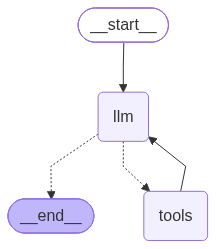

{'messages': [HumanMessage(content='北京天气怎么样？', additional_kwargs={}, response_metadata={}, id='f141d65c-560f-4a51-b99e-508a7439c98b'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 38, 'prompt_tokens': 267, 'total_tokens': 305, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 128}, 'prompt_cache_hit_tokens': 128, 'prompt_cache_miss_tokens': 139}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': '3d6116d1-6bf2-4ff1-97bf-ab1002bae50a', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a2182e-7a0c-7fd2-a350-3fd85f69edba-0', tool_calls=[{'name': 'get_weather', 'args': {'city': '北京'}, 'id': 'call_00_Y3ZA1dI8hlCpkAM4Ud512381', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 267, 'output_tokens': 38, 'total_tokens': 305, 'input_token_details': {'cache_re

In [10]:
# ReAct 工具调用
from langchain.chat_models import init_chat_model
from langchain_core.tools import tool
from langgraph.graph import MessagesState, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.messages import HumanMessage
from langgraph.constants import START
from IPython.core.display import Image
from dotenv import load_dotenv
# 定义工具
@tool
def get_weather(city: str) -> str:
    """获取某个城市的天气"""
    return f"{city}今天天气晴朗，气温在25度左右"

# 定义LLM
load_dotenv()
model = init_chat_model(
    model="deepseek-v4-flash",
    extra_body={"thinking": {"type": "disabled"}}
)

model_with_tools = model.bind_tools([get_weather])

# 定义Node
def llm_node(state: MessagesState) -> dict:
    ai_message = model_with_tools.invoke(state['messages'])
    return {"messages": [ai_message]}

# 构建Graph
graph_builder = StateGraph(MessagesState)
graph_builder.add_node("llm", llm_node)
graph_builder.add_node("tools", ToolNode([get_weather]))
graph_builder.add_edge(START, "llm")
graph_builder.add_conditional_edges("llm", tools_condition)
graph_builder.add_edge("tools", "llm")
graph = graph_builder.compile()
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))
# 执行Graph
graph.invoke({"messages": [HumanMessage("北京天气怎么样？")]})